# Lab 02 — Transfer learning và đánh giá

ResNet18 / DenseNet121; head-only → fine-tune một/hai block cuối. [EDA](01_lab02_eda.ipynb) · [Báo cáo](../walkthrough_lab_02.md) · [Registry run đang xem](../outputs/selected_run.json)

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/eda.py').exists())
sys.path.insert(0, str(ROOT))
from src import notebook_views as view
ROOT, RUN, OUT = view.context()
print('Run đã lưu:', RUN.name)

Run đã lưu: 20261024T075133Z_cifar10_cpu_full64_71863a0e


## 1. Kiến trúc và freeze/unfreeze

Classifier đổi thành 10 đầu ra. Biểu đồ so sánh tham số được học; mở phần thu gọn để xem đầy đủ cấu trúc đã lưu. [Source](../src/models.py).

Mở block cuối để thích nghi đặc trưng gần đầu ra, giữ phần đầu đã học cạnh/màu/họa tiết từ ImageNet. Đây là baseline cần kiểm chứng, không phải cấu hình tối ưu đã chứng minh. ResNet: `layer4+fc`; DenseNet: `denseblock4+norm5+classifier`. Mở hai block là candidate riêng; số tham số được mở giữa hai mạng không ngang nhau.

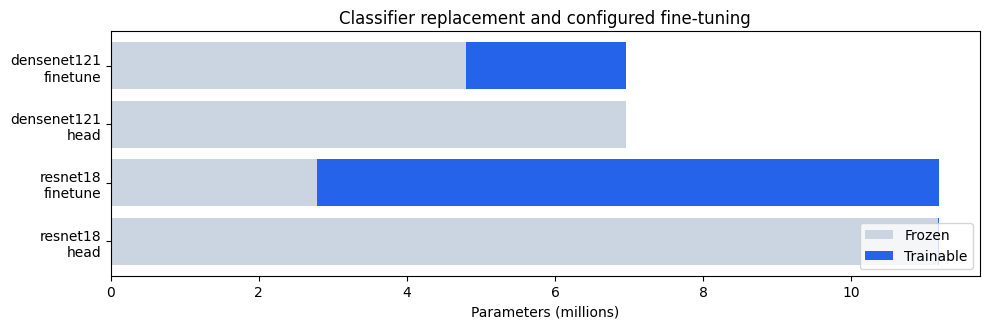

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,8398858,layer4 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,2170378,denseblock4 + norm5 + classifier


In [2]:
view.architecture_visual(RUN, OUT)

## 2. Learning rate × batch size

Grid head đã chạy; chọn candidate bằng validation theo policy của run. Notebook không dùng test để chọn cấu hình.

Hình dưới là run cũ với batch 32/64. Grid **mới** là 64/128; chưa có điểm đo cho batch 128. Batch lớn có thể giảm số bước nhưng không bảo đảm nhanh hơn, và dùng nhiều VRAM hơn.

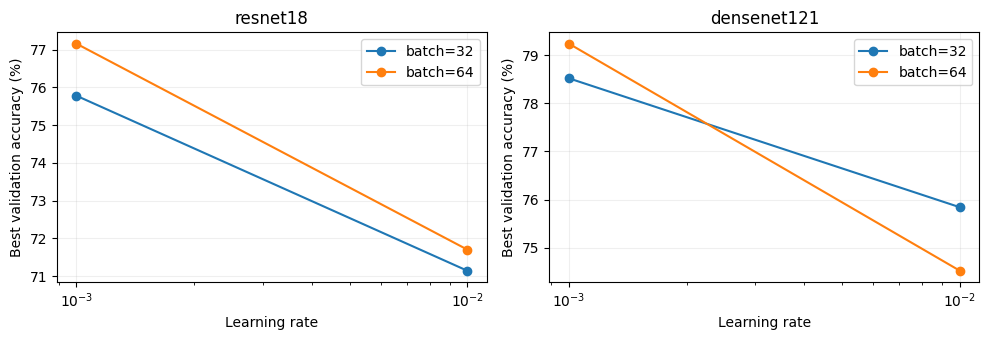

In [3]:
view.lr_search(RUN, OUT)

### Fine-tune: kế hoạch thử nghiệm, chưa phải kết quả

Mỗi dòng trong bảng là một **nhóm cấu hình sẽ thử**, không phải accuracy/loss đã đạt. LR là bước cập nhật trọng số; backbone dùng bước nhỏ để giữ đặc trưng cũ, classifier dùng LR lớn gấp 10. So sánh AdamW/SGD, mở một/hai block và LR cố định/cosine. Cùng một checkpoint head được dùng làm điểm xuất phát cho mọi candidate.

In [4]:
view.fine_search(RUN, OUT, ROOT)

,Optimizer,Backbone LR,Head LR,Opened blocks,Scheduler,Candidates,Status
0,adamw,1e-05,10 x backbone LR,last block,none,1,NOT RUN
1,adamw,"3e-06, 1e-05, 3e-05",10 x backbone LR,last block,cosine,3,NOT RUN
2,adamw,"3e-06, 1e-05, 3e-05",10 x backbone LR,last two blocks,cosine,3,NOT RUN
3,sgd,"0.0001, 0.0003, 0.001",10 x backbone LR,last block,cosine,3,NOT RUN
4,sgd,"0.0001, 0.0003, 0.001",10 x backbone LR,last two blocks,cosine,3,NOT RUN


,Head search batches,Head epochs,Fine-tune max epochs,Fine-tune minimum,Stop rule
0,"[64, 128]",10,30,10,"validation loss: patience 7, min_delta 0.0001"


## 3. Head và fine-tune: tách giai đoạn, ghi đúng epoch

Run đang xem đã chạy đủ ngân sách **head 5/5, fine-tune 2/2 epoch**, không phải ngân sách mới 10–30. Hàng trên: **HEAD ONLY**, hàng dưới: **FINE-TUNE**; xanh liền = train, cam đứt = validation; ngôi sao là checkpoint được chọn. Hai epoch fine-tune không chứng minh hội tụ.

Cấu hình mới: head 10 epoch; fine-tune min 10/max 30, dừng khi validation loss không cải thiện ít nhất 0,0001 trong 7 epoch. Bảng tách rõ ngân sách cũ đã chạy và ngân sách mới chưa chạy.

,Model,Stage,Recorded epochs,Original configured budget,New budget (NOT RUN)
0,resnet18,Head,5,5,10
1,resnet18,Fine-tune,2,2,"min 10, max 30"
2,densenet121,Head,5,5,10
3,densenet121,Fine-tune,2,2,"min 10, max 30"


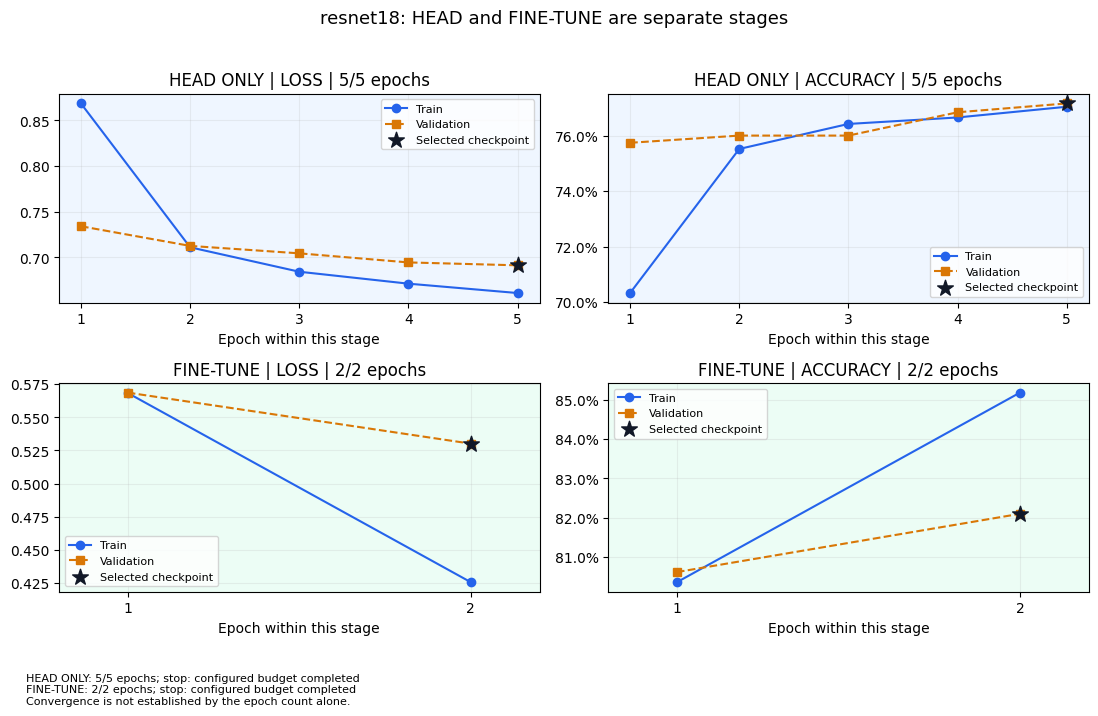

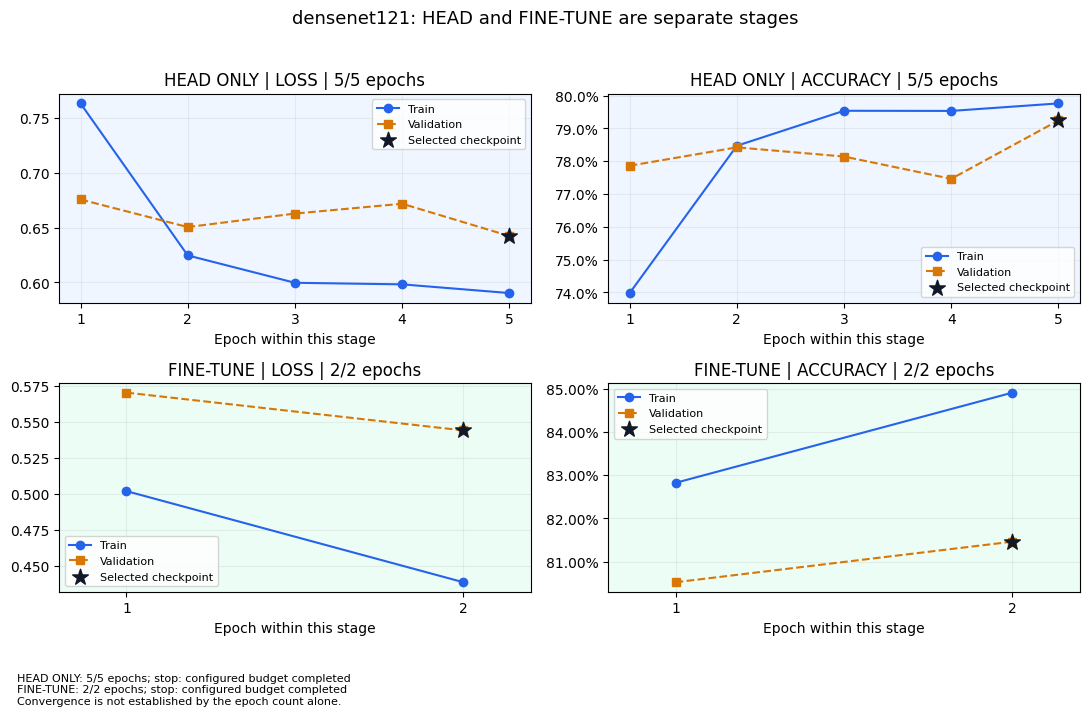

In [5]:
view.epoch_budget(RUN, ROOT)
view.learning_curves(RUN, OUT)

## 4. Chất lượng và chi phí

Đọc cùng accuracy, loss, Macro F1 và thời gian. Phân biệt toàn bộ search với selected recipe. Chỉ dùng thời gian để xếp hạng khi chính sách thực thi tương ứng; run lịch sử có cache khác nhau.

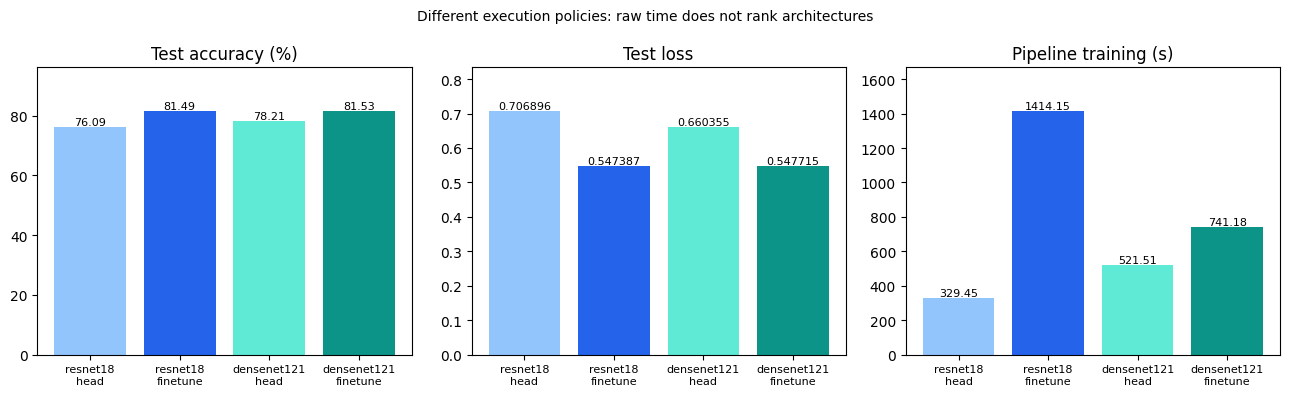

,model,stage,accuracy,loss,macro_f1,best_val_accuracy,train_seconds,pipeline_training_seconds,test_seconds,execution
0,resnet18,head,0.7609,0.7069,0.7611,0.7716,8.8886,329.4474,64.0027,pooled_feature_cache
1,resnet18,finetune,0.8149,0.5474,0.8146,0.8210,1084.6990,1414.1464,62.7633,full_image_forward
2,densenet121,head,0.7821,0.6604,0.7811,0.7924,8.9819,521.5133,100.4044,pooled_feature_cache
3,densenet121,finetune,0.8153,0.5477,0.8151,0.8146,219.6618,741.1751,92.3854,cached_frozen_prefix


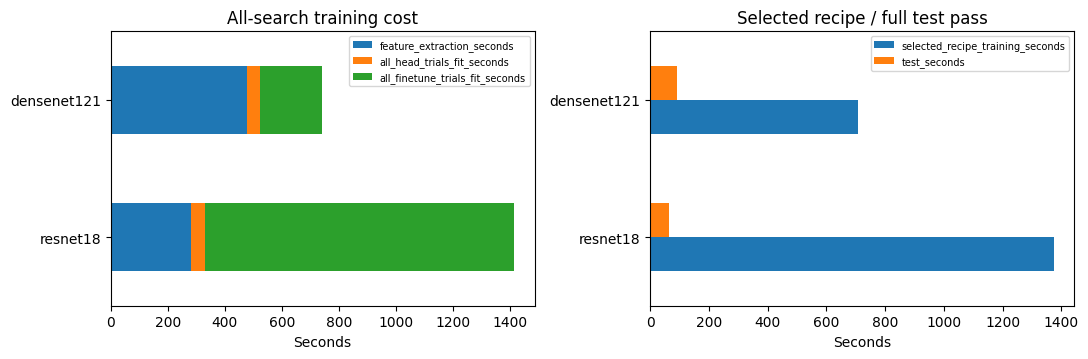

,model,execution,pipeline_training_seconds,selected_recipe_training_seconds,test_seconds
1,resnet18,full_image_forward,1414.15,1375.44,62.76
3,densenet121,cached_frozen_prefix,741.18,706.75,92.39


,model,val_accuracy,val_loss,time_comparable
0,resnet18,0.821,0.530082,False


In [6]:
view.quality_cost(RUN, OUT)
view.efficiency(RUN, OUT)

## 5. Phân tích lỗi theo lớp

Heatmap phủ precision, recall/TPR, F1 và FPR. Bảng CSV giữ toàn bộ lớp; notebook chỉ hiển thị các lớp F1 thấp nhất.

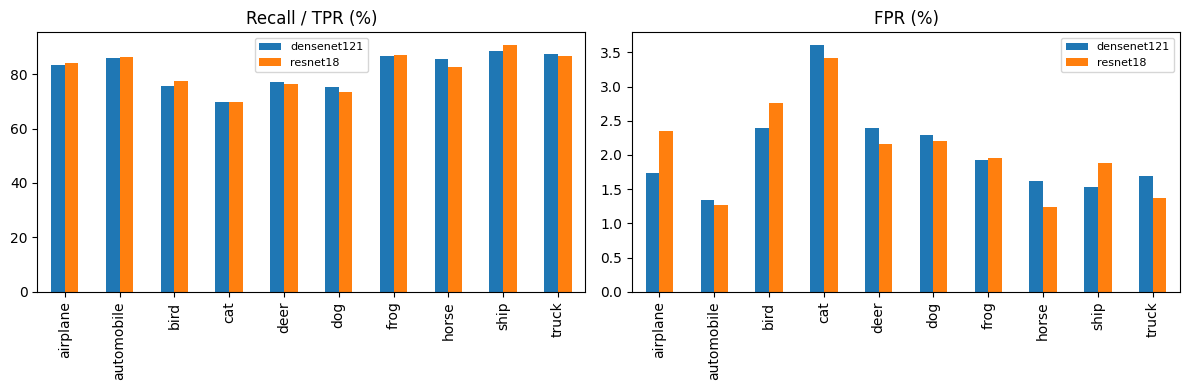

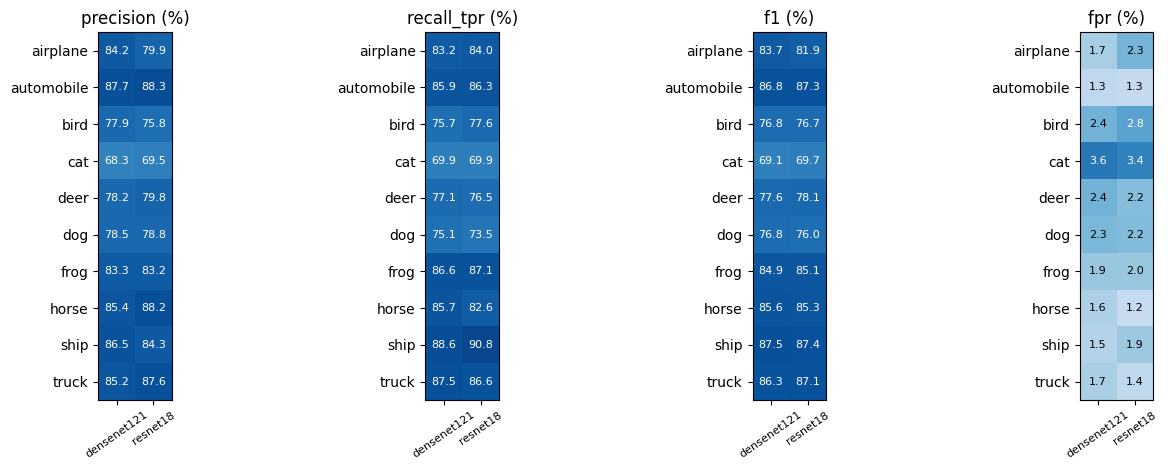

,model,stage,class,precision,recall_tpr,f1,fpr
33,densenet121,finetune,cat,0.6826,0.699,0.6907,0.0361
13,resnet18,finetune,cat,0.6948,0.699,0.6969,0.0341
15,resnet18,finetune,dog,0.7878,0.735,0.7605,0.0220
35,densenet121,finetune,dog,0.7847,0.751,0.7675,0.0229


In [7]:
view.errors(RUN, OUT)

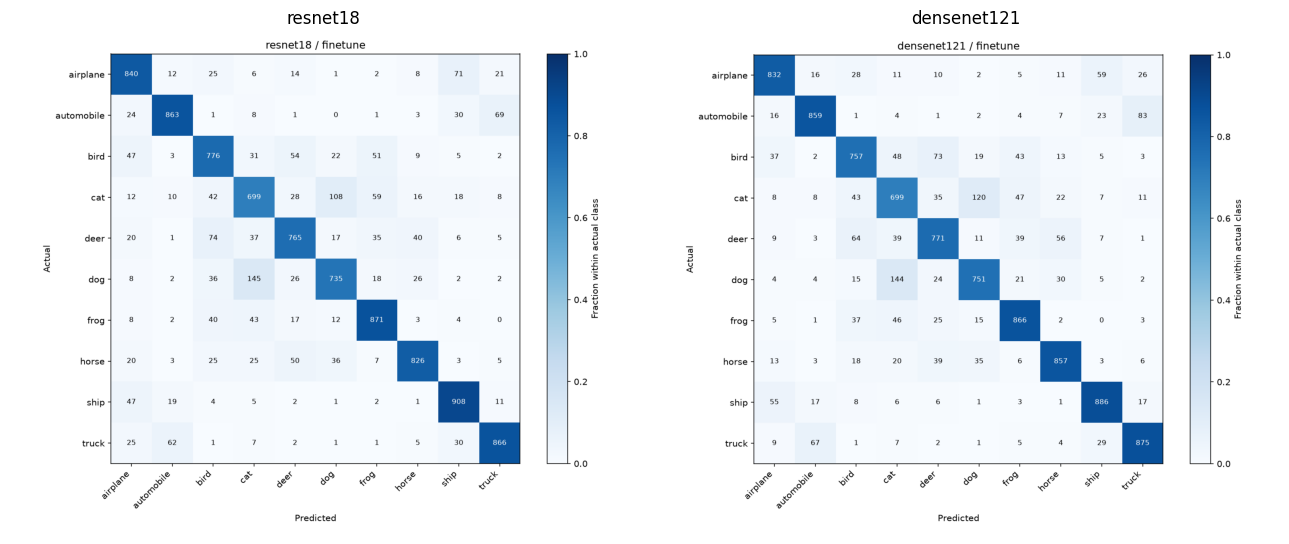

In [8]:
view.evidence(RUN, 'confusion_matrix')

Đọc confusion matrix theo hàng nhãn thật; bảng phía trên chỉ ra lớp yếu của run đang xem. Lưới dưới chọn tối đa 8 đúng và 8 sai để minh họa, không đại diện accuracy.

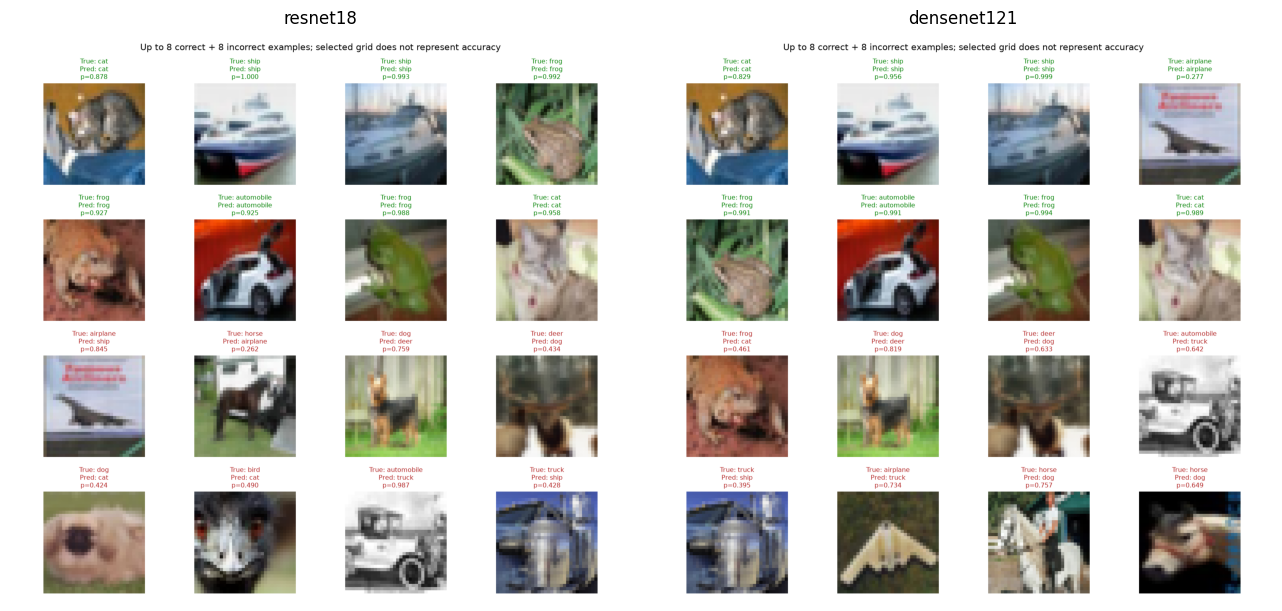

In [9]:
view.evidence(RUN, 'prediction_examples')

## 6. TensorBoard

Hình dựng từ scalar events đã lưu, không phải ảnh chụp giao diện. Mở tương tác bằng `tensorboard --logdir outputs/runs` khi có event files gốc.

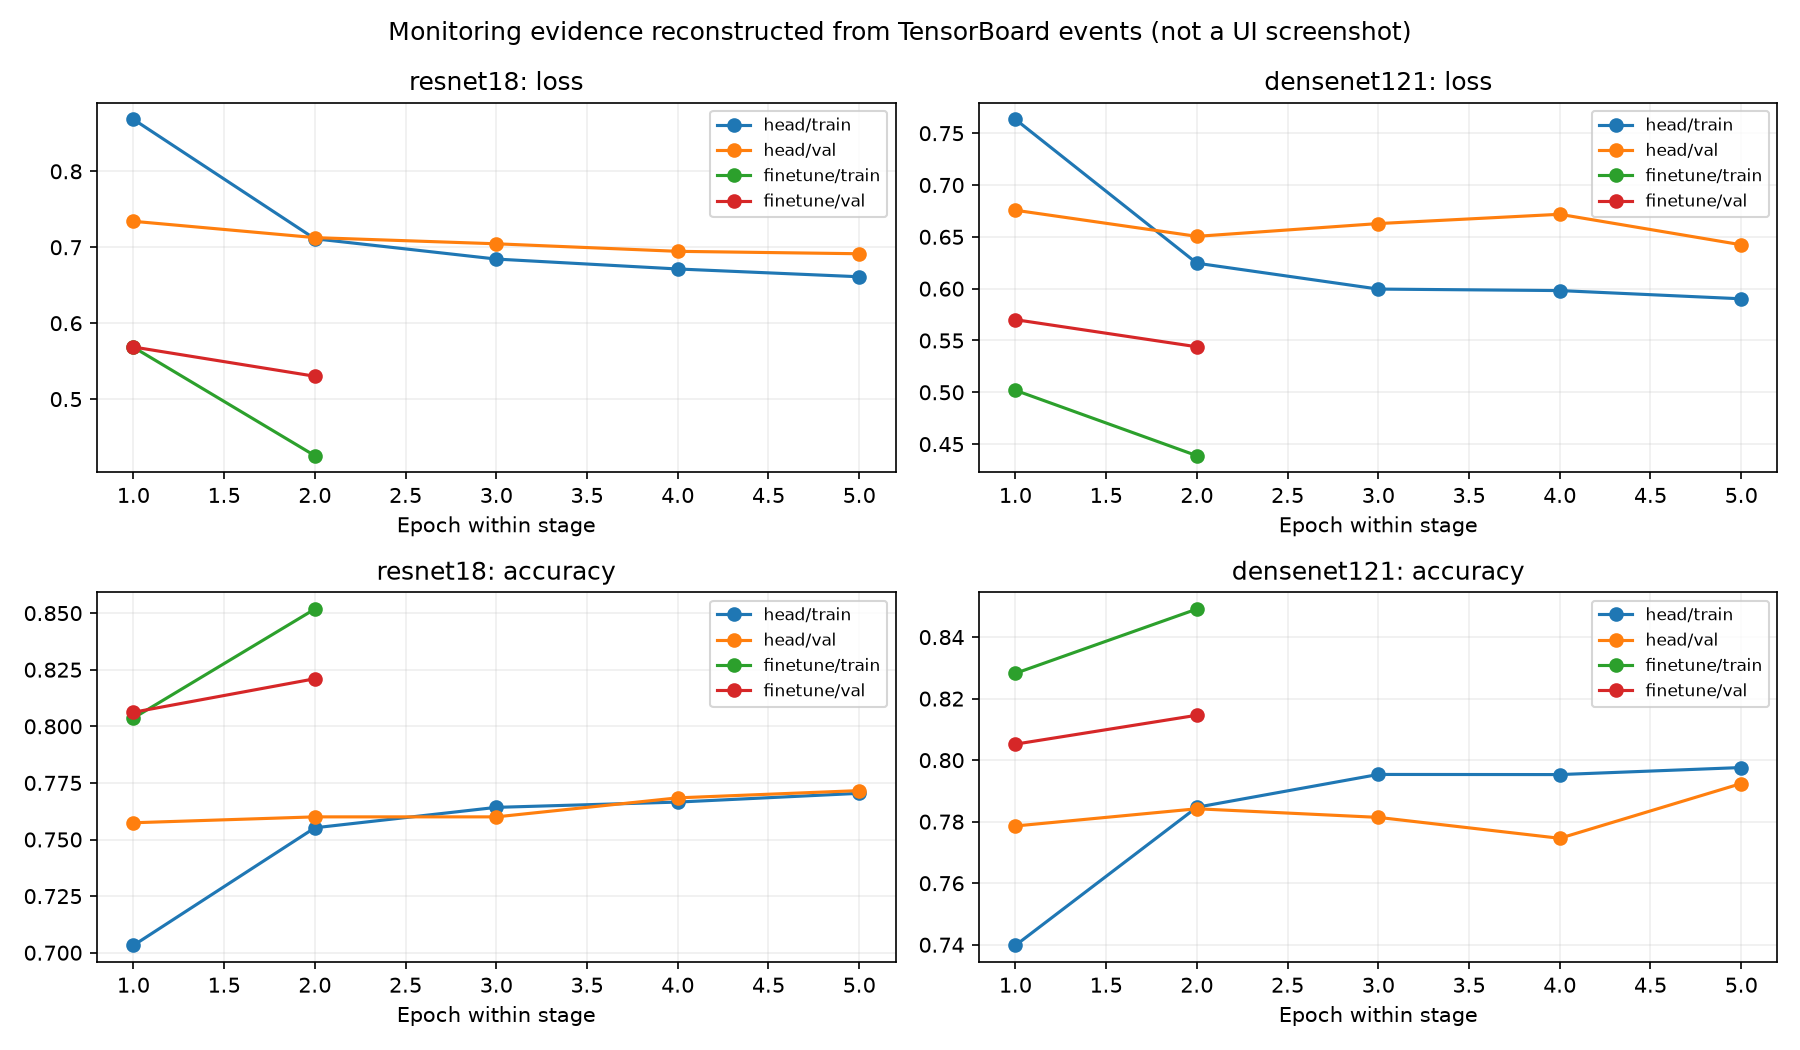

In [10]:
view.tensorboard_evidence(RUN)

## 7. Save/load và kết luận

Bảng kiểm chứng đã lưu trên 8 mẫu mỗi điều kiện; không thực hiện inference mới. Khuyến nghị theo validation và điều kiện so sánh thời gian nằm ở mục 4.

In [11]:
view.roundtrip(RUN)

,model,stage,samples,max_probability_error,passed
0,resnet18,head,8,0.0,True
1,resnet18,finetune,8,0.0,True
2,densenet121,head,8,0.0,True
3,densenet121,finetune,8,0.0,True


Tuning GPU: `python scripts/run.py --config config/tuned.json --device cuda`. Xem trước ngân sách bằng `--dry-run`; lặp seed bằng `--seed 43`/`--seed 44`, split vẫn giữ seed 42. [Source training](../src/experiment.py) · [Thiết kế và giới hạn](../walkthrough_lab_02.md#15-loss-function-and-optimization-design).

Ưu tiên chạy control đủ ngân sách trước, đọc val loss và train–val gap; sau đó so LR/optimizer/depth. Nếu vẫn underfit: xét thêm augmentation và độ phân giải 224 với ngân sách GPU, từng thay đổi riêng. Không tăng độ sâu chỉ để ép accuracy; mở sâu có thể gây overfit hoặc quên đặc trưng nguồn.